# Lab 7: ANOVA I
## Analyze Lake Contamination Data
Before you turn this assignment in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Add as many comments as you could when you solve the problem, which can help your remember what you have done.


***Submission***: For Python people, submit this Jupyter Notebook only

Name = "Noah Runions"


***Figures:*** For any figures, label axis and title clearly for full points. 

## Lab Objectives:

1. Build a one-way ANOVA table for the provided lake contamination data sets
2. Compare means with a posteriori comparisons method
3. Compare means with a priori constrasts method by hand



  
## Lab Activities: 
This lab has two parts, each is worth of 20 points. Be sure to follow the instructions and complete each parts. 

In [1]:
import pandas as pd
#import numpy as np
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f

## Part 7A (20 points). 

1. Create a data frame with data from the slides using the function pd.DataFrame 
2. Melt the data into long format for ANOVA


In [2]:
#create dataframe
data = {
    "A": [ 5,  8,  1,  2,  3,  5,  2,  2,  4,  5],
    "B": [62, 60, 58, 55, 54, 66, 62, 56, 55, 60],
    "C": [20, 20, 14, 21, 10, 15, 18, 17, 24, 19],
    "D": [24, 25, 24, 18, 20, 19, 12, 11, 18, 17],
}
df = pd.DataFrame(data)
df

,A,B,C,D
0,5,62,20,24
1,8,60,20,25
2,1,58,14,24
3,2,55,21,18
4,3,54,10,20
5,5,66,15,19
6,2,62,18,12
7,2,56,17,11
8,4,55,24,18
9,5,60,19,17


In [3]:
#your data to convert to long format for ANOVA
df_long = df.melt(var_name="Site", value_name="Concentration")
df_long

,Site,Concentration
0,A,5
1,A,8
2,A,1
3,A,2
4,A,3
5,A,5
6,A,2
7,A,2
8,A,4
9,A,5


3. Create an one way ANOVA using statmodels package
- Print to display the one-way ANOVA table
- Plot a box plot of contaminants by site as Figure 1

4. Plot the mean values for each site with error bars (mean ± standard deviation) as Figure 2. Remember to label your graphs appropriately.


In [4]:
model = ols("Concentration ~ Site", data=df_long).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

anova_table

,sum_sq,df,F,PR(>F)
Site,16862.075,3.0,385.492284,2.089390e-27
Residual,524.900,36.0,NaN,NaN


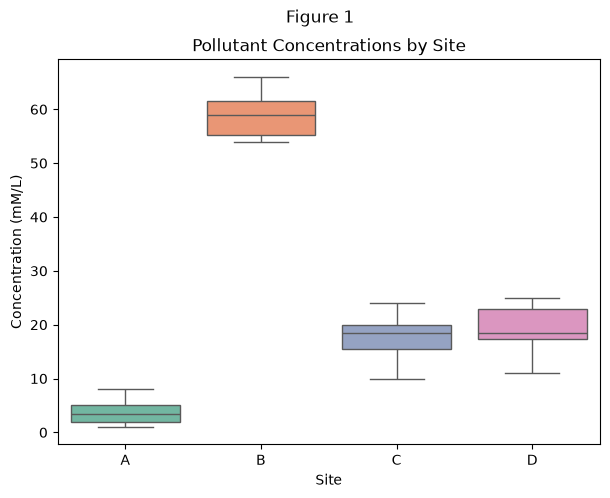

In [5]:
plt.figure(figsize=(7,5))
sns.boxplot(data = df_long,x="Site", y="Concentration", palette="Set2", hue="Site", legend=False)
plt.title("Pollutant Concentrations by Site")
plt.suptitle("Figure 1")
plt.xlabel("Site")
plt.ylabel("Concentration (mM/L)")
plt.show()

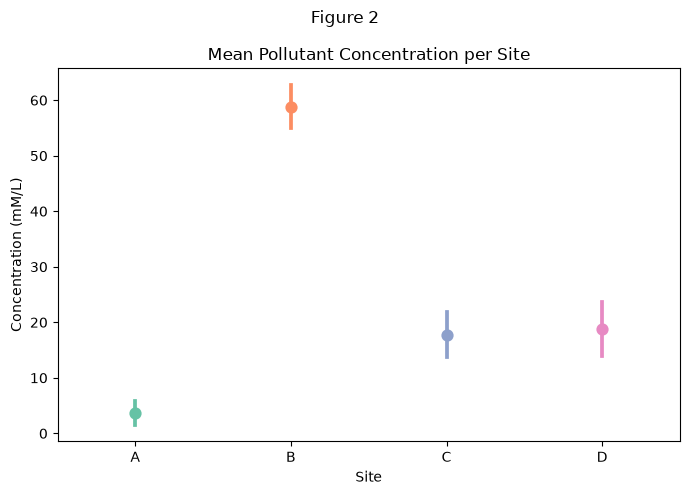

In [6]:
plt.figure(figsize=(7,5))
sns.pointplot(data=df_long, x="Site", y="Concentration", errorbar=('sd'),hue='Site', palette="Set2")
plt.title("Mean Pollutant Concentration per Site")
plt.xlabel("Site")
plt.ylabel("Concentration (mM/L)")
plt.suptitle("Figure 2")
#plt.legend()
plt.tight_layout()
plt.show()

5. Discuss the ANOVA table:
- 	State a null hypothesis regarding the data
- 	Discuss whether the null hypothesis can be rejected or accepted based on the p-value obtained

Type your answers here: \
A null hypothesis about this data might be that "distance from the facility has no impact on pollutant concentrations"\
The p-value of 2.089390e-27 is remarkably small, allowing for the rejection of the null hypothesis

6. Perform a posteriori/post hoc("after the fact") comparisons of means using the tukey analysis
- print and display the results
- also calculate the mean and standard errors by use the groupby; display the mean and standard errors
7. Plot the analysis with tukey's default plot code

In [7]:
#your code
tukey = pairwise_tukeyhsd(endog=df_long['Concentration'], #endogenous variables. i.e., the data values, the measurements you try to explain/compare
                          groups=df_long['Site'], 
                          alpha=0.05) #significance level
print(tukey)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
     A      B     55.1    0.0  50.5009  59.6991   True
     A      C     14.1    0.0   9.5009  18.6991   True
     A      D     15.1    0.0  10.5009  19.6991   True
     B      C    -41.0    0.0 -45.5991 -36.4009   True
     B      D    -40.0    0.0 -44.5991 -35.4009   True
     C      D      1.0 0.9358  -3.5991   5.5991  False
------------------------------------------------------


In [8]:
groupmeans = df_long.groupby('Site').mean()
groupsems = df_long.groupby('Site').sem()
print('Means:')
print(groupmeans)
print()
print('Standard errors:')
print(groupsems)

Means:
      Concentration
Site               
A               3.7
B              58.8
C              17.8
D              18.8

Standard errors:
      Concentration
Site               
A          0.667499
B          1.227464
C          1.263153
D          1.511438


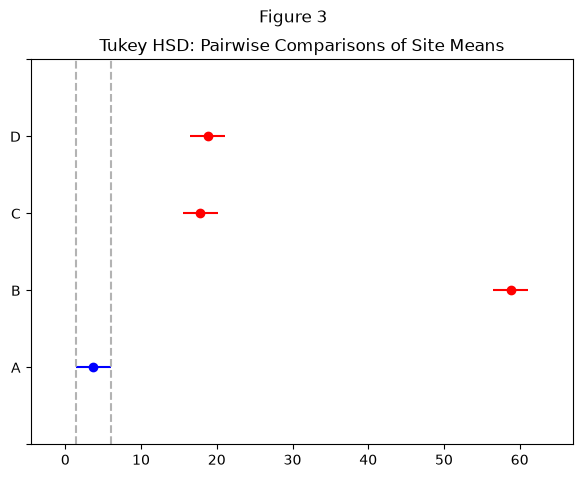

In [9]:
tukey.plot_simultaneous(comparison_name='A', figsize=(7,5))
plt.title("Tukey HSD: Pairwise Comparisons of Site Means")
plt.suptitle("Figure 3")
plt.show()

8.	Discuss the results of the posteriori comparisons 
- which groups are different/not
- why 

Groups B, C, and D are all different from group A, with group B having the largest difference and groups C and D being pretty similar \
This is likely because the facility is affecting the pollutant concentration of its surroundings, with the closest group (B) being the most impacted and the further groups (C and D) being less affected as the pollutants dilute. The control group (A) being the lowst further supports this

## Part 7B (20 pints); Compare the means using a prior contrast
1. Follow the planned contrast groups in the slides, determine if the mean values of contaminated lake sites are statistically different. 
- Before you code, explain what each contract is trying to compare:

Type your answer here: \
1: Ignoring the control, is B different than C and D? \
2: Is A different than B, C, and D? \
3: Ignoring A and B, are C and D different?

2.	Build the table of a priori contrasts for the one-way ANOVA. Some information is already calculated and contained in Part A (the anova table)

You will need to calculate the following:
- Mean square (MS) for each contrast using Equation 10.28 from the textbook. 
- The sum of square of each contrast
- Calculate the F-ratio and p-value of each contrast


In [10]:
#general steps:
#calculate the mean
#create the data frame for planned contrasts
#merge data
#calculate SS and F
#calculate p value

contrasts = pd.DataFrame({
    'Site': ['A', 'B', 'C', 'D'],
    'contrast1': [ 0,  2, -1, -1],
    'contrast2': [ 3, -1, -1, -1],
    'contrast3': [ 0,  0,  1, -1]
})

#now we can merge based on site
plannedcontrast=pd.merge(groupmeans, contrasts, on = 'Site')

plannedcontrast

,Site,Concentration,contrast1,contrast2,contrast3
0,A,3.7,0,3,0
1,B,58.8,2,-1,0
2,C,17.8,-1,-1,1
3,D,18.8,-1,-1,-1


In [11]:
ss_residual = anova_table.loc['Residual', 'sum_sq']
dof_residual = anova_table.loc['Residual', 'df']
mse = ss_residual / dof_residual
n = 10

for contrast in ('contrast1', 'contrast2', 'contrast3') :
    contrast_val = (plannedcontrast['Concentration'] * plannedcontrast[contrast]).sum()
    SScontrast = (contrast_val**2) / ((plannedcontrast[contrast]**2).sum()/n)
    print(f'SS{contrast} = {SScontrast}')
    F_contrast = SScontrast / mse
    print(f'F_{contrast} = {F_contrast}')
    p_value = 1 - f.cdf(F_contrast, 1, dof_residual)
    print(f'{contrast} p_val = {p_value}')

SScontrast1 = 10935.0
F_contrast1 = 749.9714231282148
contrast1 p_val = 0.0
SScontrast2 = 5922.075
F_contrast2 = 406.1625071442179
contrast2 p_val = 0.0
SScontrast3 = 5.0
F_contrast3 = 0.34292246142122307
contrast3 p_val = 0.5618005075301


4.	Discuss the results of the a priori contrast. Does the data support the constrast? Why do you expect to such trend(combining the sites description from the slides)?


You can type your answer here:\
The results show that B is different from C and D, that B, C, and D are different from A, and that there is no significant difference between C and D \
The data supports this, as B, C, and D are all higher than A, with B being significantly higher \
This is expected if the facility is contributing to nearby pollutants as B, the closest, would be the most affected; C and D, further away, would still be affected but less so (as the pollutants would dilute somewhat so far out); and A, the control, would be lowest as it isn't affecxted by the facility